In [10]:
from pathlib import Path
import os
import zipfile
import yaml
import random
import shutil
from collections import Counter

import matplotlib.pyplot as plt
from PIL import Image

In [11]:
%pip install pyyaml matplotlib pillow

Note: you may need to restart the kernel to use updated packages.


In [13]:
import zipfile
from pathlib import Path

old_zip_path = Path("smoking.v1i.yolov8.zip")
old_dataset_path = Path("Smoking_Old_Dataset")

old_dataset_path.mkdir(exist_ok=True)

with zipfile.ZipFile(old_zip_path, "r") as zip_ref:
    zip_ref.extractall(old_dataset_path)

print("Old Dataset extracted successfully!")
print("Dataset path:", old_dataset_path.resolve())
print("Contents:", [p.name for p in old_dataset_path.iterdir()])

Old Dataset extracted successfully!
Dataset path: C:\Users\Fix-Dell\Downloads\Smoking_Detection\Smoking_Old_Dataset
Contents: ['data.yaml', 'README.dataset.txt', 'README.roboflow.txt', 'test', 'train', 'valid']


In [14]:
new_zip_path = Path("Smoking Detection.v5i.yolov8.zip")
new_dataset_path = Path("Smoking_Dataset")

new_dataset_path.mkdir(exist_ok=True)

with zipfile.ZipFile(new_zip_path, "r") as zip_ref:
    zip_ref.extractall(new_dataset_path)

print("New Dataset extracted successfully!")
print("Dataset path:", new_dataset_path.resolve())
print("Contents:", [p.name for p in new_dataset_path.iterdir()])

New Dataset extracted successfully!
Dataset path: C:\Users\Fix-Dell\Downloads\Smoking_Detection\Smoking_Dataset
Contents: ['data.yaml', 'README.dataset.txt', 'README.roboflow.txt', 'test', 'train', 'valid']


In [15]:
datasets = {
    "Old Dataset": old_dataset_path,
    "New Dataset": new_dataset_path
}

for name, path in datasets.items():
    print(name, ":", path.resolve())

Old Dataset : C:\Users\Fix-Dell\Downloads\Smoking_Detection\Smoking_Old_Dataset
New Dataset : C:\Users\Fix-Dell\Downloads\Smoking_Detection\Smoking_Dataset


In [17]:
import yaml

configs = {}
dataset_classes = {}
dataset_roots = {}
target_class_ids = {}

for name, path in datasets.items():

    yaml_path = path / "data.yaml"

    if not yaml_path.exists():
        raise FileNotFoundError(f"data.yaml not found in {name}")

    with open(yaml_path, "r", encoding="utf-8") as f:
        config = yaml.safe_load(f)

    configs[name] = config
    dataset_roots[name] = path

    class_names = config["names"]

    if isinstance(class_names, dict):
        class_names = [
            class_names[k]
            for k in sorted(class_names, key=lambda x: int(x))
        ]

    dataset_classes[name] = class_names

    target_name = "smoking" if name == "Old Dataset" else "smoke"

    matches = [
        i for i, class_name in enumerate(class_names)
        if str(class_name).strip().lower() == target_name
    ]

    if not matches:
        raise ValueError(f"Target class not found in {name}: {class_names}")

    target_class_ids[name] = matches[0]

    print("\nDataset:", name)
    print(yaml.dump(config, sort_keys=False, allow_unicode=True))
    print("Classes:", class_names)
    print("Number of classes:", len(class_names))
    print("Target class:", target_name)
    print("Target class ID:", target_class_ids[name])


Dataset: Old Dataset
train: ../train/images
val: ../valid/images
test: ../test/images
nc: 2
names:
- no_vest
- smoking
roboflow:
  workspace: database-m3leo
  project: smoking-wdoa5
  version: 1
  license: CC BY 4.0
  url: https://universe.roboflow.com/database-m3leo/smoking-wdoa5/dataset/1

Classes: ['no_vest', 'smoking']
Number of classes: 2
Target class: smoking
Target class ID: 1

Dataset: New Dataset
train: ../train/images
val: ../valid/images
test: ../test/images
nc: 1
names:
- smoke
roboflow:
  workspace: kyunghee-university-ada5d
  project: smoking-detection-3gefl
  version: 5
  license: CC BY 4.0
  url: https://universe.roboflow.com/kyunghee-university-ada5d/smoking-detection-3gefl/dataset/5

Classes: ['smoke']
Number of classes: 1
Target class: smoke
Target class ID: 0


In [18]:
from pathlib import Path
from collections import Counter

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

dataset_images = {}
dataset_labels = {}

for name, root in dataset_roots.items():

    image_files = [
        p for p in root.rglob("*")
        if p.is_file()
        and p.suffix.lower() in image_extensions
        and "images" in p.parts
    ]

    label_files = [
        p for p in root.rglob("*.txt")
        if "labels" in p.parts
    ]

    dataset_images[name] = image_files
    dataset_labels[name] = label_files

    print("\nDataset:", name)
    print("Total Images:", len(image_files))
    print("Total Label Files:", len(label_files))

    print("\nImages by folder:")
    print(Counter(str(p.parent.relative_to(root)) for p in image_files))

    print("\nLabels by folder:")
    print(Counter(str(p.parent.relative_to(root)) for p in label_files))

print("\nTotal Images:",
      sum(len(images) for images in dataset_images.values()))


Dataset: Old Dataset
Total Images: 97
Total Label Files: 97

Images by folder:
Counter({'train\\images': 89, 'valid\\images': 4, 'test\\images': 4})

Labels by folder:
Counter({'train\\labels': 89, 'valid\\labels': 4, 'test\\labels': 4})

Dataset: New Dataset
Total Images: 18230
Total Label Files: 18230

Images by folder:
Counter({'train\\images': 16758, 'valid\\images': 740, 'test\\images': 732})

Labels by folder:
Counter({'train\\labels': 16758, 'valid\\labels': 740, 'test\\labels': 732})

Total Images: 18327


In [19]:
def expected_label_path(image_path):

    parts = list(image_path.parts)

    if "images" in parts:
        idx = len(parts) - 1 - parts[::-1].index("images")
        parts[idx] = "labels"

        return Path(*parts).with_suffix(".txt")

    return None

dataset_matched = {}
dataset_missing = {}

for name, image_files in dataset_images.items():

    matched = []
    missing_labels = []

    for img_path in image_files:

        label_path = expected_label_path(img_path)

        if label_path is not None and label_path.exists():
            matched.append((img_path, label_path))
        else:
            missing_labels.append(img_path)

    dataset_matched[name] = matched
    dataset_missing[name] = missing_labels

    print("\nDataset:", name)
    print("Images with matching labels:", len(matched))
    print("Images missing labels:", len(missing_labels))

    if missing_labels:
        print("Missing label examples:", missing_labels[:5])


Dataset: Old Dataset
Images with matching labels: 97
Images missing labels: 0

Dataset: New Dataset
Images with matching labels: 18230
Images missing labels: 0


In [20]:
from collections import Counter
import math

dataset_class_counts = {}
dataset_invalid_rows = {}
dataset_empty_labels = {}

for name, matched in dataset_matched.items():

    valid_rows = 0
    invalid_rows = []
    class_counts = Counter()
    empty_label_files = 0

    class_names = dataset_classes[name]

    for img_path, label_path in matched:

        lines = [
            line.strip()
            for line in label_path.read_text(encoding="utf-8").splitlines()
            if line.strip()
        ]

        if not lines:
            empty_label_files += 1
            continue

        for line_number, line in enumerate(lines, 1):

            parts = line.split()

            try:
                if len(parts) != 5:
                    raise ValueError("Expected 5 values")

                class_id = int(parts[0])
                x, y, w, h = map(float, parts[1:])

                if not all(math.isfinite(v) for v in [x, y, w, h]):
                    raise ValueError("Non-finite coordinates")

                if not 0 <= class_id < len(class_names):
                    raise ValueError("Invalid class ID")

                if not all(0 <= v <= 1 for v in [x, y, w, h]):
                    raise ValueError("Coordinates outside 0..1")

                if w <= 0 or h <= 0:
                    raise ValueError("Invalid bounding box size")

                if (x - w / 2 < -1e-6 or
                    x + w / 2 > 1 + 1e-6 or
                    y - h / 2 < -1e-6 or
                    y + h / 2 > 1 + 1e-6):
                    raise ValueError("Box outside image")

                valid_rows += 1
                class_counts[class_id] += 1

            except Exception as e:
                invalid_rows.append(
                    (str(label_path), line_number, line, str(e))
                )

    dataset_class_counts[name] = class_counts
    dataset_invalid_rows[name] = invalid_rows
    dataset_empty_labels[name] = empty_label_files

    print("\nDataset:", name)
    print("Valid Annotation Rows:", valid_rows)
    print("Empty Label Files:", empty_label_files)
    print("Invalid Annotation Rows:", len(invalid_rows))

    print("\nAnnotations by Class:")

    for class_id, count in sorted(class_counts.items()):
        print(class_names[class_id], ":", count)

    if invalid_rows:
        print("Invalid Examples:", invalid_rows[:5])


Dataset: Old Dataset
Valid Annotation Rows: 190
Empty Label Files: 0
Invalid Annotation Rows: 0

Annotations by Class:
no_vest : 147
smoking : 43

Dataset: New Dataset
Valid Annotation Rows: 25527
Empty Label Files: 47
Invalid Annotation Rows: 6

Annotations by Class:
smoke : 25527
Invalid Examples: [('Smoking_Dataset\\train\\labels\\smoking_0960_jpg.rf.1604c250efec9fa47b9c5b6aaf9bc8b9.txt', 1, '0 0.445476403125 0.6584374953125 0.42379645000000005 0.6753871375 0.45084634531249995 0.6888839890625 0.4664591265625 0.6807769875 0.46128336093750005 0.6661126203125 0.4460143828125 0.660331009375 0.445476403125 0.6584374953125', 'Expected 5 values'), ('Smoking_Dataset\\train\\labels\\smoking_0960_jpg.rf.7b2941a5819830a8428aa8f21e9f15ba.txt', 1, '0 0.4847785578125 0.6698843390625 0.46885353125 0.6662840250000001 0.4680572609375 0.6644838109375 0.4489472296875 0.684285765625 0.4776122765625 0.6938866499999999 0.4919448375 0.683685665625 0.4847785578125 0.6698843390625', 'Expected 5 values'), (


Dataset: Old Dataset
Images with Target: 43


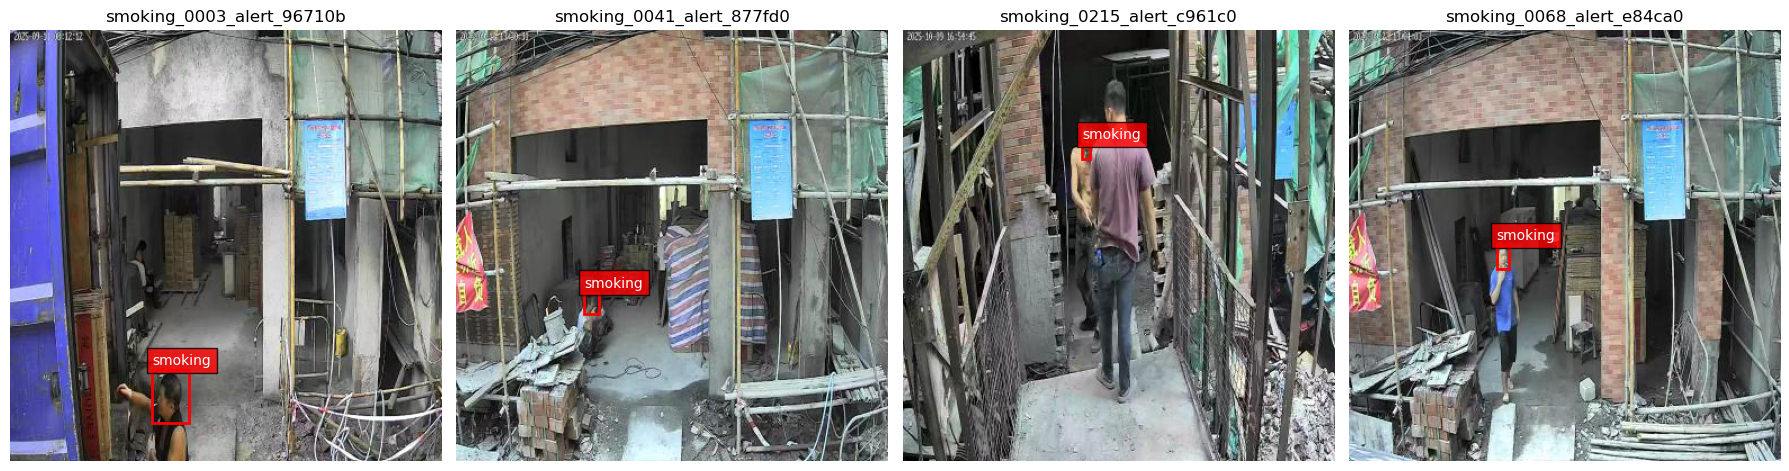


Dataset: New Dataset
Images with Target: 18177


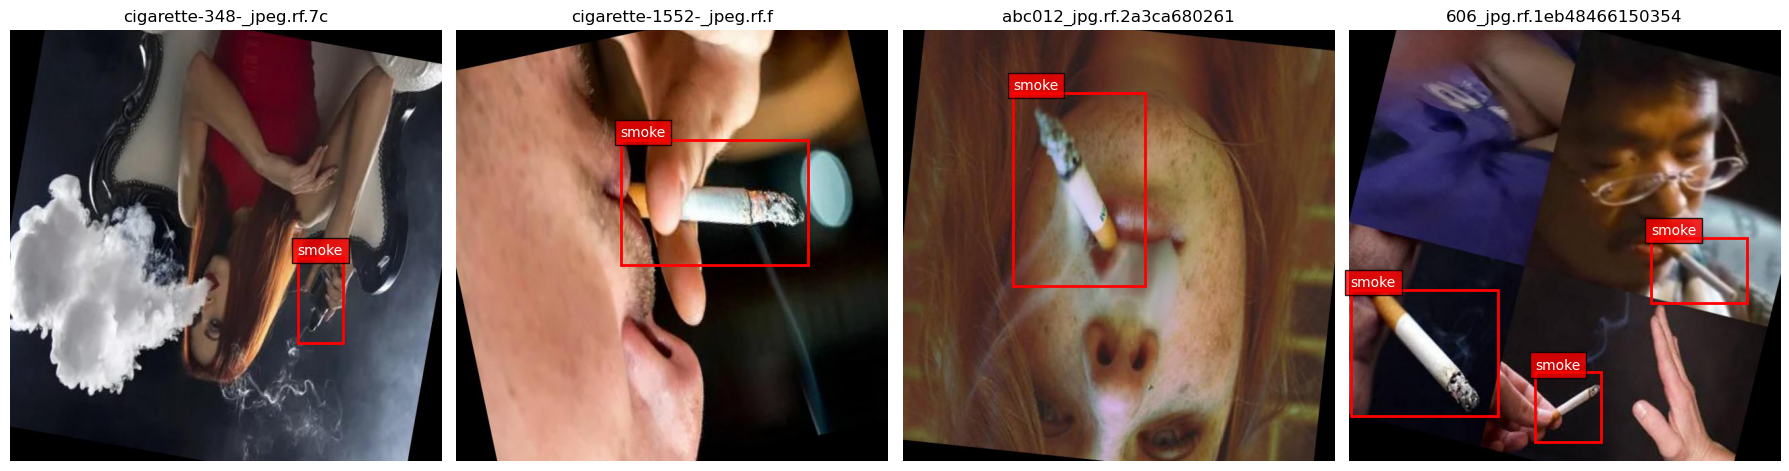

In [21]:
import random
import matplotlib.pyplot as plt
from PIL import Image

smoking_samples = {}

random.seed(42)

for name, matched in dataset_matched.items():

    target_id = target_class_ids[name]
    samples_with_target = []

    for img_path, label_path in matched:

        lines = label_path.read_text(encoding="utf-8").splitlines()

        if any(
            len(parts := line.split()) == 5
            and int(parts[0]) == target_id
            for line in lines if line.strip()
        ):
            samples_with_target.append((img_path, label_path))

    smoking_samples[name] = samples_with_target

    samples = random.sample(
        samples_with_target,
        min(4, len(samples_with_target))
    )

    print("\nDataset:", name)
    print("Images with Target:", len(samples_with_target))

    fig, axes = plt.subplots(1, 4, figsize=(18, 5))

    for ax in axes:
        ax.axis("off")

    for ax, (img_path, label_path) in zip(axes, samples):

        image = Image.open(img_path).convert("RGB")
        width, height = image.size

        ax.imshow(image)
        ax.set_title(img_path.name[:25])

        for line in label_path.read_text(encoding="utf-8").splitlines():

            parts = line.split()

            if len(parts) != 5 or int(parts[0]) != target_id:
                continue

            xc, yc, bw, bh = map(float, parts[1:])

            x1 = (xc - bw / 2) * width
            y1 = (yc - bh / 2) * height

            ax.add_patch(
                plt.Rectangle(
                    (x1, y1),
                    bw * width,
                    bh * height,
                    fill=False,
                    edgecolor="red",
                    linewidth=2
                )
            )

            ax.text(
                x1, max(0, y1 - 5),
                dataset_classes[name][target_id],
                color="white",
                bbox=dict(facecolor="red", alpha=0.8)
            )

    plt.tight_layout()
    plt.show()

In [22]:
total_images = 0

for name, root in dataset_roots.items():

    print("\nDataset:", name)

    dataset_total = 0

    for split in ["train", "valid", "val", "test"]:

        image_dir = root / split / "images"

        if not image_dir.exists():
            continue

        images = [
            p for p in image_dir.iterdir()
            if p.is_file() and p.suffix.lower() in image_extensions
        ]

        print(f"{split}: {len(images)} images")

        dataset_total += len(images)

    print("Total:", dataset_total)
    total_images += dataset_total

print("\nTotal Images in Both Datasets:", total_images)


Dataset: Old Dataset
train: 89 images
valid: 4 images
test: 4 images
Total: 97

Dataset: New Dataset
train: 16758 images
valid: 740 images
test: 732 images
Total: 18230

Total Images in Both Datasets: 18327


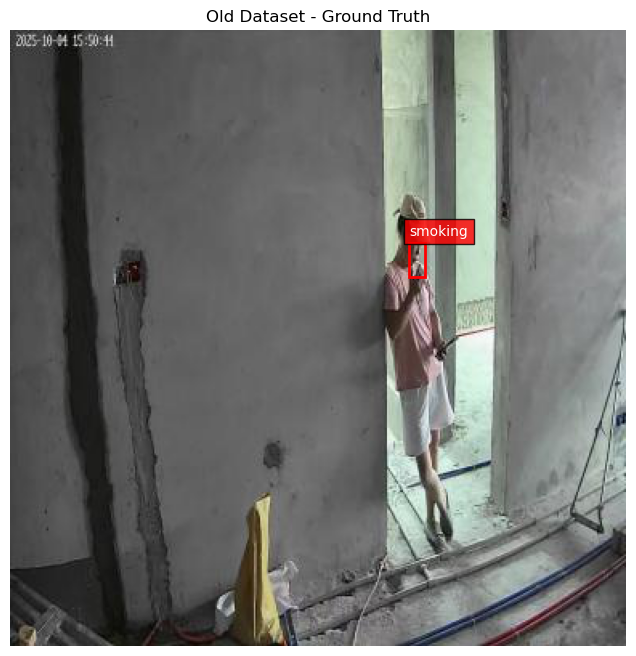

Saved: C:\Users\Fix-Dell\Downloads\Smoking_Detection\Smoking_Samples\old_dataset_annotated.png


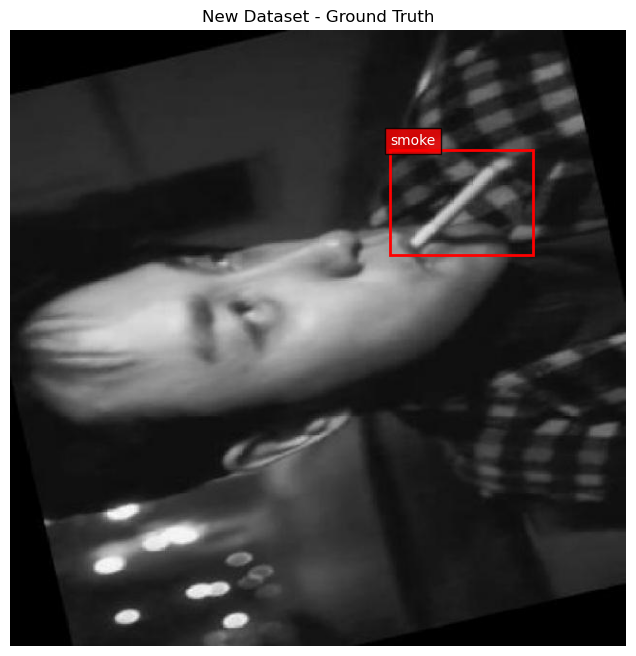

Saved: C:\Users\Fix-Dell\Downloads\Smoking_Detection\Smoking_Samples\new_dataset_annotated.png


In [23]:
sample_output = Path("Smoking_Samples")
sample_output.mkdir(exist_ok=True)

for name, samples in smoking_samples.items():

    if not samples:
        print("No target samples found:", name)
        continue

    target_id = target_class_ids[name]

    img_path, label_path = samples[0]

    image = Image.open(img_path).convert("RGB")
    width, height = image.size

    fig, ax = plt.subplots(figsize=(12, 8))

    ax.imshow(image)
    ax.axis("off")
    ax.set_title(f"{name} - Ground Truth")

    for line in label_path.read_text(encoding="utf-8").splitlines():

        parts = line.split()

        if len(parts) != 5 or int(parts[0]) != target_id:
            continue

        xc, yc, bw, bh = map(float, parts[1:])

        x1 = (xc - bw / 2) * width
        y1 = (yc - bh / 2) * height

        ax.add_patch(
            plt.Rectangle(
                (x1, y1),
                bw * width,
                bh * height,
                fill=False,
                edgecolor="red",
                linewidth=2
            )
        )

        ax.text(
            x1, max(0, y1 - 5),
            dataset_classes[name][target_id],
            color="white",
            bbox=dict(facecolor="red", alpha=0.8)
        )

    output_path = sample_output / (
        name.lower().replace(" ", "_") + "_annotated.png"
    )

    plt.savefig(output_path, bbox_inches="tight", dpi=200)
    plt.show()

    print("Saved:", output_path.resolve())

In [24]:
dataset_links = {
    "Old Dataset": "https://universe.roboflow.com/database-m3leo/smoking-wdoa5",
    "New Dataset": "https://universe.roboflow.com/kyunghee-university-ada5d/smoking-detection-3gefl/dataset/5"
}

for name in datasets:

    config = configs[name]
    target_id = target_class_ids[name]

    license_info = config.get(
        "license",
        config.get("roboflow", {}).get("license", "Not specified")
    )

    print("\nDataset:", name)
    print("Link:", dataset_links[name])
    print("Dataset Root:", dataset_roots[name])
    print("Total Images:", len(dataset_images[name]))
    print("Images with Matching Labels:", len(dataset_matched[name]))
    print("Classes:", dataset_classes[name])
    print("Target Annotations:", dataset_class_counts[name].get(target_id, 0))
    print("Empty Label Files:", dataset_empty_labels[name])
    print("Invalid Annotation Rows:", len(dataset_invalid_rows[name]))
    print("License:", license_info)

print("\nQuality Notes")

print("Old Dataset:")
print("- Contains CCTV-like frames.")
print("- Contains smoking and no_vest labels.")
print("- no_vest is irrelevant to the smoking detection task.")
print("- Limited dataset size.")

print("\nNew Dataset:")
print("- Contains the smoke class.")
print("- Includes different image angles and environments.")
print("- Not all images resemble CCTV footage.")
print("- Bounding box consistency requires visual inspection.")

print("\nExperiment Plan")
print("1. Inspect images and labels from both datasets.")
print("2. Check target class and annotation consistency.")
print("3. Remove irrelevant no_vest annotations.")
print("4. Merge compatible smoking annotations.")
print("5. Train a YOLOv8 baseline.")
print("6. Evaluate precision, recall and mAP.")
print("7. Save inference results and model weights.")


Dataset: Old Dataset
Link: https://universe.roboflow.com/database-m3leo/smoking-wdoa5
Dataset Root: Smoking_Old_Dataset
Total Images: 97
Images with Matching Labels: 97
Classes: ['no_vest', 'smoking']
Target Annotations: 43
Empty Label Files: 0
Invalid Annotation Rows: 0
License: CC BY 4.0

Dataset: New Dataset
Link: https://universe.roboflow.com/kyunghee-university-ada5d/smoking-detection-3gefl/dataset/5
Dataset Root: Smoking_Dataset
Total Images: 18230
Images with Matching Labels: 18230
Classes: ['smoke']
Target Annotations: 25527
Empty Label Files: 47
Invalid Annotation Rows: 6
License: CC BY 4.0

Quality Notes
Old Dataset:
- Contains CCTV-like frames.
- Contains smoking and no_vest labels.
- no_vest is irrelevant to the smoking detection task.
- Limited dataset size.

New Dataset:
- Contains the smoke class.
- Includes different image angles and environments.
- Not all images resemble CCTV footage.
- Bounding box consistency requires visual inspection.

Experiment Plan
1. Inspect 

In [32]:
import shutil
import hashlib
from pathlib import Path
from collections import Counter

output_root = Path("Combined_Smoking_Dataset")

if output_root.exists():
    shutil.rmtree(output_root)

output_root.mkdir(parents=True, exist_ok=True)

print("Combined Dataset folder is ready")

split_map = {
    "train": "train",
    "valid": "valid",
    "val": "valid",
    "test": "test"
}

seen_hashes = {}
copied_counts = Counter()
duplicate_counts = Counter()
excluded_counts = Counter()
converted_polygon_counts = Counter()
invalid_label_counts = Counter()

for name, root in dataset_roots.items():

    target_id = target_class_ids[name]
    prefix = "old" if name == "Old Dataset" else "new"

    for source_split, target_split in split_map.items():

        source_images = root / source_split / "images"
        source_labels = root / source_split / "labels"

        if not source_images.exists():
            continue

        image_dir = output_root / target_split / "images"
        label_dir = output_root / target_split / "labels"

        image_dir.mkdir(parents=True, exist_ok=True)
        label_dir.mkdir(parents=True, exist_ok=True)

        for img in sorted(source_images.iterdir()):

            if not img.is_file() or img.suffix.lower() not in image_extensions:
                continue

            label_file = source_labels / f"{img.stem}.txt"

            if not label_file.exists():
                excluded_counts[name] += 1
                continue

            raw_lines = [
                line.strip()
                for line in label_file.read_text(encoding="utf-8").splitlines()
                if line.strip()
            ]

            target_lines = []
            other_classes = False
            invalid_file = False

            for line in raw_lines:
                parts = line.split()

                try:
                    class_id = int(parts[0])

                    if class_id != target_id:
                        other_classes = True
                        continue

                    coords = list(map(float, parts[1:]))

                    if len(parts) == 5:
                        xc, yc, w, h = coords

                    # حالة Polygon / Segmentation
                    elif len(coords) >= 6 and len(coords) % 2 == 0:
                        xs = coords[0::2]
                        ys = coords[1::2]

                        x_min, x_max = min(xs), max(xs)
                        y_min, y_max = min(ys), max(ys)

                        xc = (x_min + x_max) / 2
                        yc = (y_min + y_max) / 2
                        w = x_max - x_min
                        h = y_max - y_min

                        converted_polygon_counts[name] += 1

                    else:
                        raise ValueError("Unsupported label format")

                    # Validation
                    if not all(0 <= v <= 1 for v in [xc, yc, w, h]):
                        raise ValueError("Coordinates outside 0..1")

                    if w <= 0 or h <= 0:
                        raise ValueError("Invalid box size")

                    if xc - w / 2 < -1e-6 or xc + w / 2 > 1 + 1e-6:
                        raise ValueError("Box outside image")

                    if yc - h / 2 < -1e-6 or yc + h / 2 > 1 + 1e-6:
                        raise ValueError("Box outside image")

                    target_lines.append(
                        f"0 {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}"
                    )

                except Exception:
                    invalid_file = True
                    invalid_label_counts[name] += 1
                    break

            if invalid_file:
                excluded_counts[name] += 1
                continue

            if not target_lines and other_classes:
                excluded_counts[name] += 1
                continue

            if not target_lines and name == "Old Dataset":
                excluded_counts[name] += 1
                continue

            image_hash = hashlib.sha256(img.read_bytes()).hexdigest()

            if image_hash in seen_hashes:
                duplicate_counts[name] += 1
                continue

            seen_hashes[image_hash] = target_split

            new_name = f"{prefix}_{img.name}"

            shutil.copy2(img, image_dir / new_name)

            new_label = label_dir / f"{Path(new_name).stem}.txt"
            new_label.write_text(
                "\n".join(target_lines),
                encoding="utf-8"
            )

            copied_counts[(name, target_split)] += 1

print("\nCopied Images:")
for key, count in copied_counts.items():
    print(key, ":", count)

print("\nExact Duplicates Skipped:")
print(dict(duplicate_counts))

print("\nImages Excluded:")
print(dict(excluded_counts))

print("\nPolygon Labels Converted to Bounding Boxes:")
print(dict(converted_polygon_counts))

print("\nInvalid Label Files Skipped:")
print(dict(invalid_label_counts))

Combined Dataset folder is ready

Copied Images:
('Old Dataset', 'train') : 37
('Old Dataset', 'valid') : 2
('Old Dataset', 'test') : 4
('New Dataset', 'train') : 16641
('New Dataset', 'valid') : 737
('New Dataset', 'test') : 732

Exact Duplicates Skipped:
{'New Dataset': 120}

Images Excluded:
{'Old Dataset': 54}

Polygon Labels Converted to Bounding Boxes:
{'New Dataset': 6}

Invalid Label Files Skipped:
{}


In [33]:
import yaml

combined_yaml = output_root / "data.yaml"

combined_config = {
    "path": str(output_root.resolve()),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "nc": 1,
    "names": ["smoking"]
}

with open(combined_yaml, "w", encoding="utf-8") as f:
    yaml.safe_dump(
        combined_config,
        f,
        sort_keys=False
    )

print("Combined Dataset Created!")
print("YAML Path:", combined_yaml.resolve())

for split in ["train", "valid", "test"]:

    image_dir = output_root / split / "images"
    label_dir = output_root / split / "labels"

    images = list(image_dir.iterdir()) if image_dir.exists() else []
    labels = list(label_dir.glob("*.txt")) if label_dir.exists() else []

    print(f"\n{split}")
    print("Images:", len(images))
    print("Labels:", len(labels))

Combined Dataset Created!
YAML Path: C:\Users\Fix-Dell\Downloads\Smoking_Detection\Combined_Smoking_Dataset\data.yaml

train
Images: 16678
Labels: 16678

valid
Images: 739
Labels: 739

test
Images: 736
Labels: 736


In [35]:
%pip install ultralytics

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   -------------- ------------------------- 0.5/1.4 MB 3.8 MB/s eta 0:00:01
   ----------------------------- ---------- 1.0/1.4 MB 3.4 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 3.2 MB/s  0:00:00
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
    --------------------------------------- 0.8/44.0 MB 4.0 MB/s eta 0:00:11
   - -------------------------------------- 1.6/44.0 MB 4.0 MB/s eta 0:00:11
   -- ------------------------------------- 2.4/44.0 MB 3.9 MB/s eta 0:00:11
   -- ------------------------------------- 3.1/44.0 MB 3.9 MB/s eta 0:00:11
   --- ------------------------------------ 3.9/44.0 MB 3.9 MB/s eta 0:00:11
   ---- ----------------------------------- 4.7/44.0 MB 3.9 MB/s eta 0:00:11
   ----- ---------------------------------- 5.5/44.0 MB 3.9 MB/s eta 0:00:10
   ----- ---------------------------------- 6.3/44.0 MB 3.9 MB/s eta 0:00:10
   ------ ----------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [37]:
from pathlib import Path

print("Current Directory:", Path.cwd())

for folder in ["smoking_training", "runs"]:
    path = Path(folder)

    if path.exists():
        for file in path.rglob("*.pt"):
            print("Found Model:", file.resolve())

Current Directory: c:\Users\Fix-Dell\Downloads\Smoking_Detection
Found Model: C:\Users\Fix-Dell\Downloads\Smoking_Detection\runs\detect\smoking_training\combined_smoking\weights\best.pt
Found Model: C:\Users\Fix-Dell\Downloads\Smoking_Detection\runs\detect\smoking_training\combined_smoking\weights\last.pt


In [ ]:
from ultralytics import YOLO
from pathlib import Path

model = YOLO("yolov8n.pt")

results = model.train(
    data=str(combined_yaml.resolve()),
    epochs=10,
    imgsz=640,
    batch=8,
    patience=10,
    project="smoking_training",
    name="combined_smoking",
    exist_ok=True
)


In [39]:
from pathlib import Path
import pandas as pd

training_path = Path(
    "runs/detect/smoking_training/combined_smoking"
)

results_path = training_path / "results.csv"

if results_path.exists():
    df = pd.read_csv(results_path)
    display(df)
else:
    print("Training results.csv not found")

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,2943.73,2.07801,2.42727,1.91938,0.45917,0.34017,0.33795,0.14065,2.06717,2.16496,1.94646,0.000666,0.000666,0.000666
1,2,6356.05,2.02352,2.02913,1.89295,0.53363,0.45856,0.47132,0.21176,2.00362,1.84903,1.83825,0.001201,0.001201,0.001201
2,3,21253.40,1.95865,1.90031,1.86220,0.54726,0.54095,0.53243,0.23237,1.92727,1.70139,1.86388,0.001604,0.001604,0.001604
3,4,54225.50,1.89920,1.81065,1.82004,0.56618,0.59037,0.55498,0.26970,1.77104,1.56758,1.72587,0.001406,0.001406,0.001406
4,5,59420.40,1.83252,1.69248,1.75870,0.66299,0.60537,0.66175,0.31907,1.74819,1.49091,1.68738,0.001208,0.001208,0.001208
5,6,64418.10,1.78028,1.59308,1.71893,0.67908,0.61642,0.67267,0.35320,1.65352,1.40334,1.62688,0.001010,0.001010,0.001010
6,7,67114.60,1.73821,1.52211,1.67695,0.70721,0.65391,0.71739,0.37976,1.62634,1.31711,1.60568,0.000812,0.000812,0.000812
7,8,70704.10,1.68884,1.44280,1.64577,0.75751,0.68903,0.76002,0.40822,1.59744,1.22885,1.57796,0.000614,0.000614,0.000614
8,9,74122.40,1.64140,1.36952,1.59942,0.77248,0.70745,0.78054,0.42467,1.55962,1.20165,1.55730,0.000416,0.000416,0.000416
9,10,78279.60,1.59903,1.30442,1.56659,0.80853,0.73086,0.80795,0.44976,1.52738,1.14584,1.52094,0.000218,0.000218,0.000218


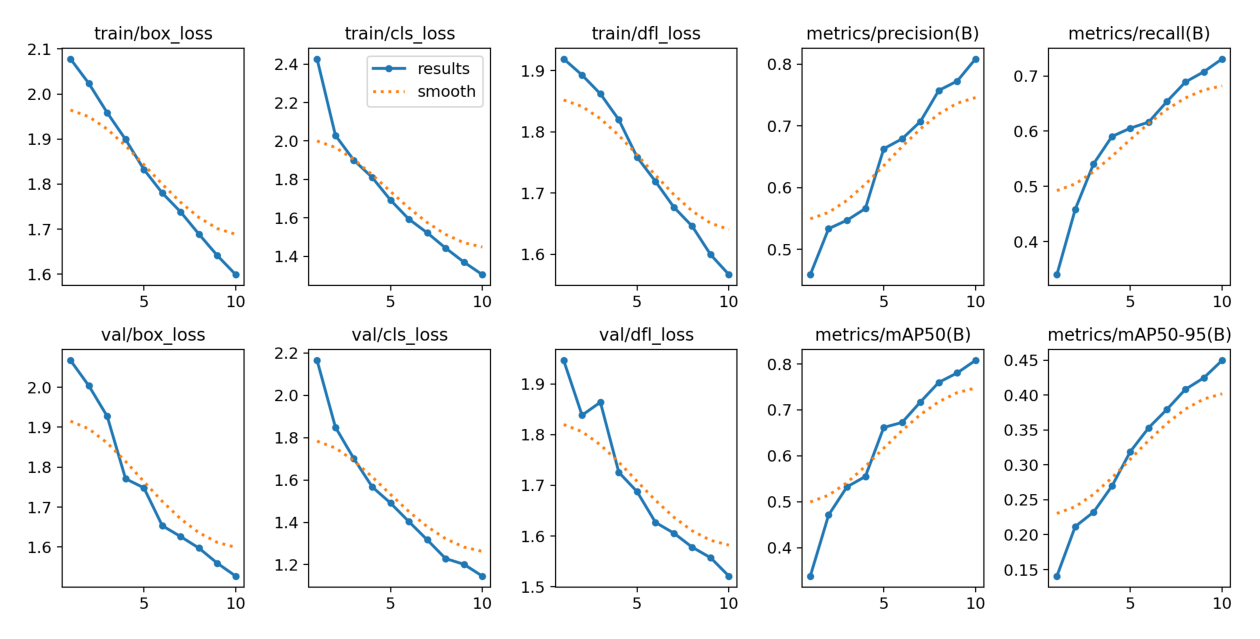

In [40]:
from PIL import Image
import matplotlib.pyplot as plt

results_image = training_path / "results.png"

if results_image.exists():
    plt.figure(figsize=(16, 10))
    plt.imshow(Image.open(results_image))
    plt.axis("off")
    plt.show()
else:
    print("Training results.png not found")

In [38]:
from pathlib import Path
from ultralytics import YOLO

best_weights = Path(
    "runs/detect/smoking_training/combined_smoking/weights/best.pt"
)

if not best_weights.exists():
    raise FileNotFoundError("best.pt not found")

best_model = YOLO(str(best_weights))

print("Training Completed!")
print("Best Model:", best_weights.resolve())

Training Completed!
Best Model: C:\Users\Fix-Dell\Downloads\Smoking_Detection\runs\detect\smoking_training\combined_smoking\weights\best.pt


Models Loaded Successfully!

Previously Measured Test Results
Precision: 0.8201695620188502
Recall: 0.7178631051752922
mAP50: 0.7965431267105227
mAP50-95: 0.4652857624354295
These are previous evaluation results, not new measurements.

Selected CCTV Image: old_smoking_0003_alert_96710bc0bedc4057b57194b7a2d96d22_jpg.rf.c0cdeee03e8c1a57f52b9d8828b839ca.jpg
Detected Persons: 3


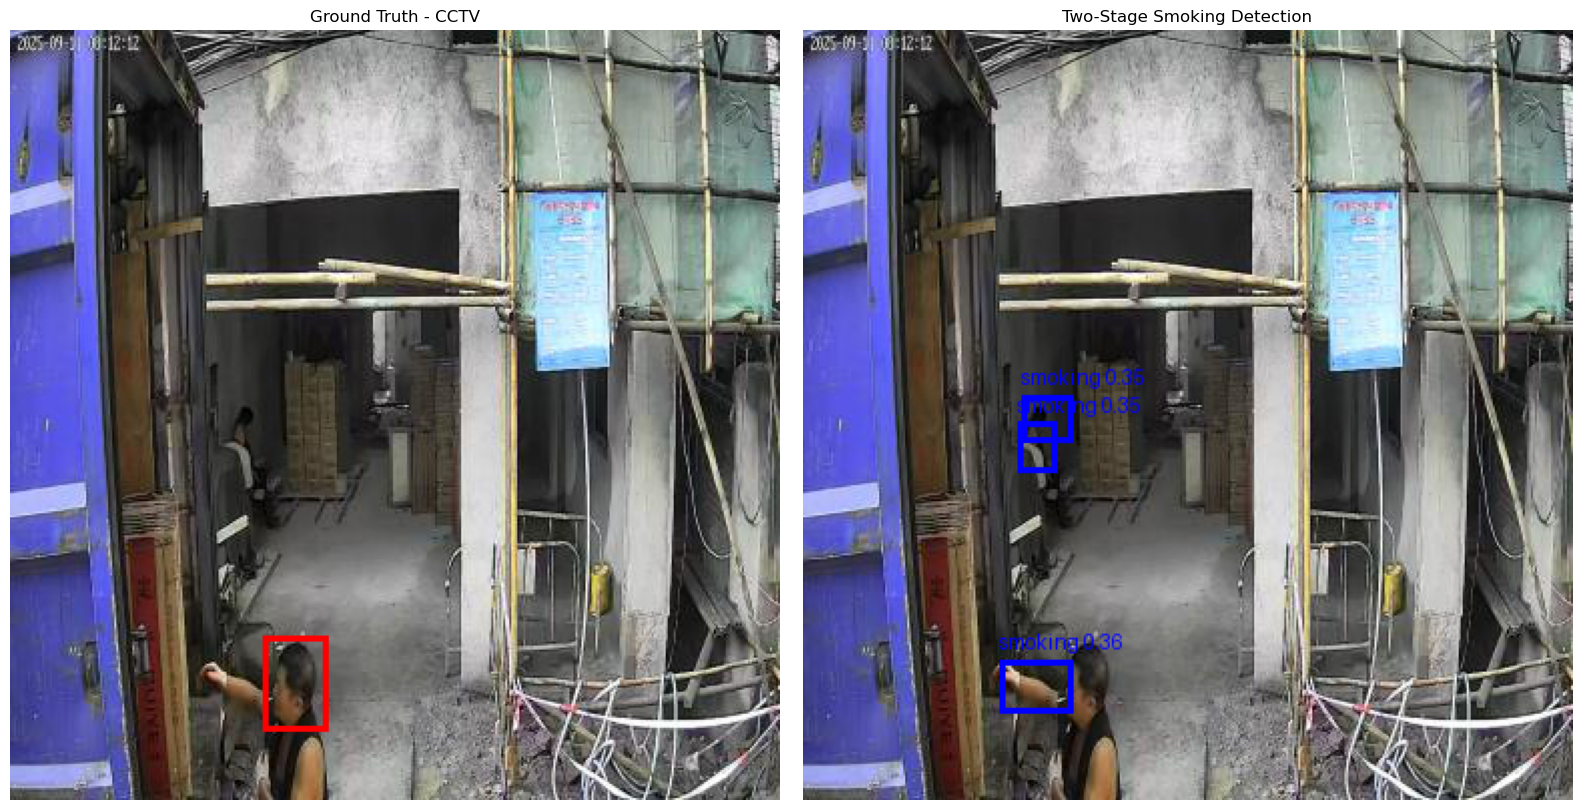


Inference Results
Ground Truth Boxes: 1
Predicted Smoking Boxes: 3
Smoking Confidence: 0.3579
Smoking Confidence: 0.3533
Smoking Confidence: 0.352
Result Saved: C:\Users\Fix-Dell\Downloads\Smoking_Detection\Smoking_Detection_Results\two_stage_cctv_comparison.png
Model Weights: C:\Users\Fix-Dell\Downloads\Smoking_Detection\runs\detect\smoking_training\combined_smoking\weights\best.pt


In [ ]:

from ultralytics import YOLO
from PIL import Image, ImageDraw
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

project_dir = Path(
    r"C:\Users\Fix-Dell\Downloads\Smoking_Detection"
)

best_weights = project_dir / "runs/detect/smoking_training/combined_smoking/weights/best.pt"
output_root = project_dir / "Combined_Smoking_Dataset"

if not best_weights.exists():
    raise FileNotFoundError(f"Model not found: {best_weights}")

smoking_model = YOLO(str(best_weights))
person_model = YOLO("yolov8n.pt")

print("Models Loaded Successfully!")

print("\nPreviously Measured Test Results")
print("Precision:", 0.8201695620188502)
print("Recall:", 0.7178631051752922)
print("mAP50:", 0.7965431267105227)
print("mAP50-95:", 0.4652857624354295)
print("These are previous evaluation results, not new measurements.")

test_dir = output_root / "test" / "images"
label_dir = output_root / "test" / "labels"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

old_test_images = sorted([
    p for p in test_dir.iterdir()
    if p.name.startswith("old_")
    and p.suffix.lower() in image_extensions
])

if len(old_test_images) < 2:
    raise ValueError("CCTV test image not found")

test_image = old_test_images[1]

image = Image.open(test_image).convert("RGB")
width, height = image.size

print("\nSelected CCTV Image:", test_image.name)

# Stage 1: Person Detection

person_results = person_model.predict(
    source=str(test_image),
    classes=[0],
    conf=0.25,
    imgsz=960,
    verbose=False
)[0]

print("Detected Persons:", len(person_results.boxes))

# Stage 2: Smoking Detection Inside Person Crops

all_boxes = []

for person_box in person_results.boxes:

    px1, py1, px2, py2 = map(
        int, person_box.xyxy[0].tolist()
    )

    person_width = px2 - px1
    person_height = py2 - py1

    if person_width < 15 or person_height < 30:
        continue

    x1 = max(0, int(px1 - person_width * 0.3))
    y1 = max(0, int(py1 - person_height * 0.1))
    x2 = min(width, int(px2 + person_width * 0.3))
    y2 = min(height, int(py1 + person_height * 0.75))

    crop = image.crop((x1, y1, x2, y2))

    result = smoking_model.predict(
        source=np.array(crop),
        imgsz=960,
        conf=0.20,
        iou=0.45,
        verbose=False
    )[0]

    for box in result.boxes:

        bx1, by1, bx2, by2 = box.xyxy[0].tolist()
        confidence = float(box.conf[0])

        all_boxes.append((
            bx1 + x1,
            by1 + y1,
            bx2 + x1,
            by2 + y1,
            confidence
        ))

# Remove Overlapping Predictions

def calculate_iou(box_a, box_b):

    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])
    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area_a = max(0, box_a[2] - box_a[0]) * max(0, box_a[3] - box_a[1])
    area_b = max(0, box_b[2] - box_b[0]) * max(0, box_b[3] - box_b[1])

    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0

selected_boxes = []

for box in sorted(all_boxes, key=lambda b: b[4], reverse=True):

    if all(calculate_iou(box, kept) < 0.5 for kept in selected_boxes):
        selected_boxes.append(box)

# Ground Truth

ground_truth = image.copy()
gt_draw = ImageDraw.Draw(ground_truth)

label_path = label_dir / f"{test_image.stem}.txt"

ground_truth_boxes = 0

if label_path.exists():

    for line in label_path.read_text().splitlines():

        parts = line.split()

        if len(parts) != 5:
            continue

        cls, xc, yc, bw, bh = map(float, parts)

        x1 = (xc - bw / 2) * width
        y1 = (yc - bh / 2) * height
        x2 = (xc + bw / 2) * width
        y2 = (yc + bh / 2) * height

        gt_draw.rectangle(
            (x1, y1, x2, y2),
            outline="red",
            width=3
        )

        ground_truth_boxes += 1

# Improved Prediction

annotated = image.copy()
pred_draw = ImageDraw.Draw(annotated)

for x1, y1, x2, y2, confidence in selected_boxes:

    pred_draw.rectangle(
        (x1, y1, x2, y2),
        outline="blue",
        width=3
    )

    pred_draw.text(
        (x1, max(0, y1 - 15)),
        f"smoking {confidence:.2f}",
        fill="blue"
    )

# Display Results

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(ground_truth)
axes[0].set_title("Ground Truth - CCTV")
axes[0].axis("off")

axes[1].imshow(annotated)
axes[1].set_title("Two-Stage Smoking Detection")
axes[1].axis("off")

plt.tight_layout()

result_folder = project_dir / "Smoking_Detection_Results"
result_folder.mkdir(parents=True, exist_ok=True)

output_path = result_folder / "two_stage_cctv_comparison.png"

plt.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print("\nInference Results")
print("Ground Truth Boxes:", ground_truth_boxes)
print("Predicted Smoking Boxes:", len(selected_boxes))

for box in selected_boxes:
    print("Smoking Confidence:", round(box[4], 4))

if not selected_boxes:
    print("No smoking detected at the selected confidence threshold.")

print("Result Saved:", output_path.resolve())
print("Model Weights:", best_weights.resolve())



Smoking Detection Error Analysis
Confidence Threshold: 0.25
IoU Threshold: 0.5

Dataset: Old CCTV
Images Tested: 4
True Positives: 0
False Positives: 1
False Negatives: 4
Sample Precision: 0.0
Sample Recall: 0.0

Dataset: New Dataset
Images Tested: 16
True Positives: 30
False Positives: 14
False Negatives: 11
Sample Precision: 0.6818
Sample Recall: 0.7317


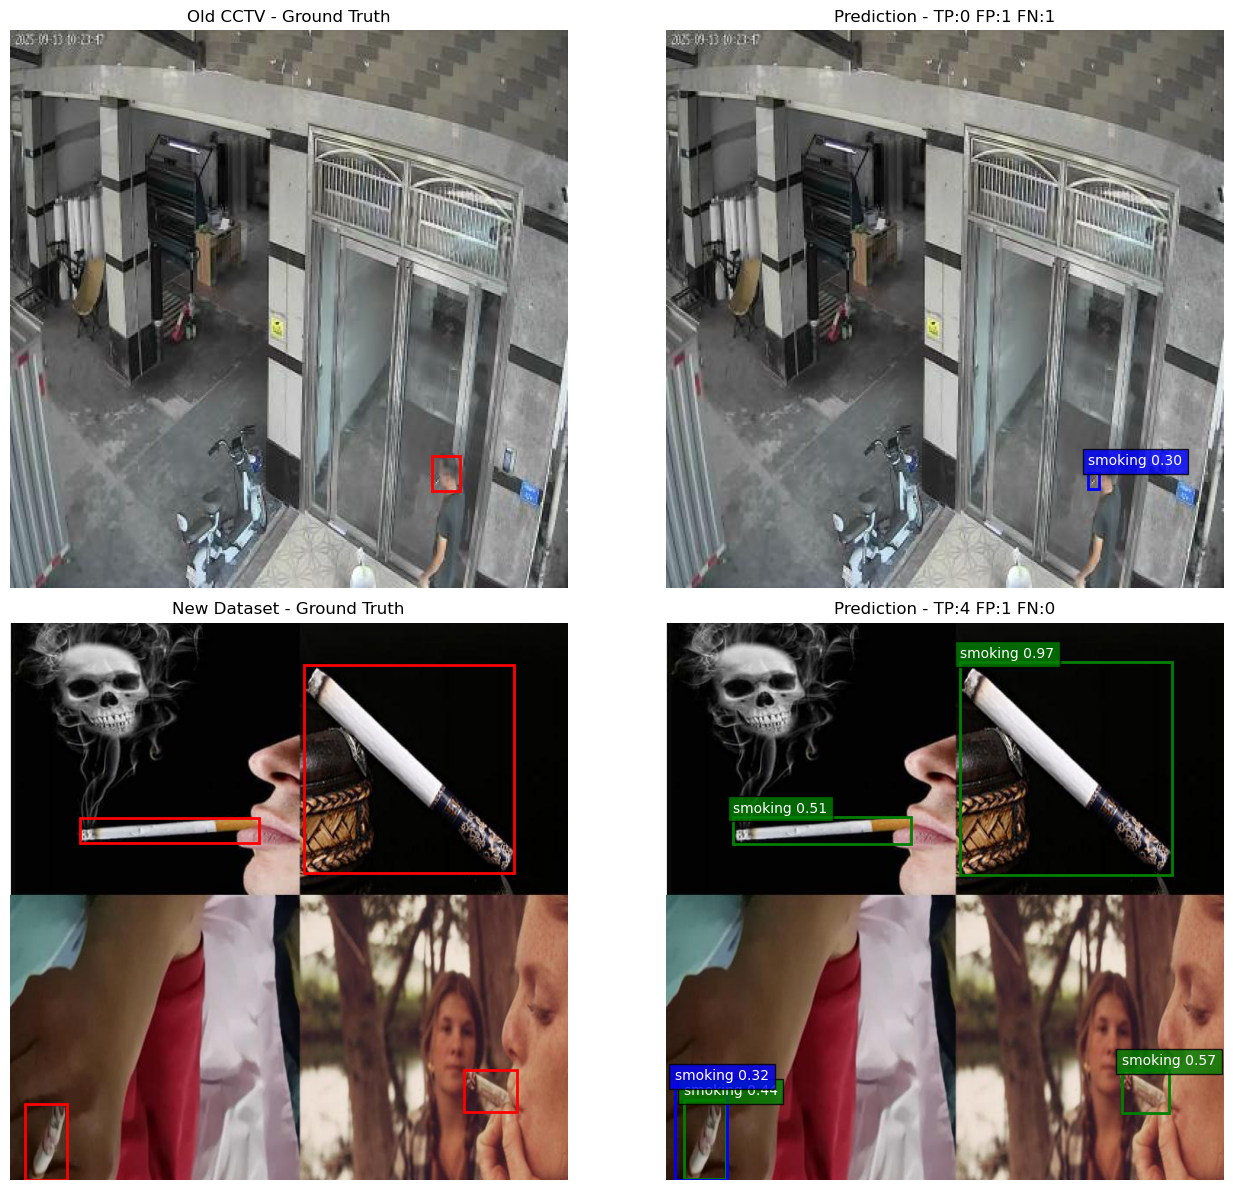


Results Saved:
Comparison: C:\Users\Fix-Dell\Downloads\Smoking_Detection\Smoking_Detection_Results\smoking_error_analysis.png
CSV: C:\Users\Fix-Dell\Downloads\Smoking_Detection\Smoking_Detection_Results\smoking_error_analysis.csv
Model: C:\Users\Fix-Dell\Downloads\Smoking_Detection\runs\detect\smoking_training\combined_smoking\weights\best.pt


In [ ]:
from ultralytics import YOLO
from PIL import Image
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random
import pandas as pd

project_dir = Path(
    r"C:\Users\Fix-Dell\Downloads\Smoking_Detection"
)

best_weights = project_dir / "runs/detect/smoking_training/combined_smoking/weights/best.pt"
test_dir = project_dir / "Combined_Smoking_Dataset/test/images"
label_dir = project_dir / "Combined_Smoking_Dataset/test/labels"

result_folder = project_dir / "Smoking_Detection_Results"
result_folder.mkdir(parents=True, exist_ok=True)

if not best_weights.exists():
    raise FileNotFoundError(f"Model not found: {best_weights}")

best_model = YOLO(str(best_weights))

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

old_images = sorted([
    p for p in test_dir.iterdir()
    if p.name.startswith("old_") and p.suffix.lower() in image_extensions
])

new_images = sorted([
    p for p in test_dir.iterdir()
    if p.name.startswith("new_") and p.suffix.lower() in image_extensions
])

random.seed(42)

selected_images = old_images + random.sample(
    new_images, min(16, len(new_images))
)

conf_threshold = 0.25
iou_threshold = 0.50


def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


results = []

for img_path in selected_images:

    image = Image.open(img_path).convert("RGB")
    width, height = image.size

    label_path = label_dir / f"{img_path.stem}.txt"

    gt_boxes = []

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()

            if len(parts) != 5 or int(parts[0]) != 0:
                continue

            xc, yc, bw, bh = map(float, parts[1:])

            gt_boxes.append((
                (xc - bw / 2) * width,
                (yc - bh / 2) * height,
                (xc + bw / 2) * width,
                (yc + bh / 2) * height
            ))

    prediction = best_model.predict(
        source=str(img_path),
        conf=conf_threshold,
        imgsz=640,
        verbose=False
    )[0]

    pred_boxes = [
        (
            box.xyxy[0].tolist(),
            float(box.conf[0])
        )
        for box in prediction.boxes
    ]

    matched_gt = set()
    matched_predictions = set()
    best_matched_iou = 0

    for i, (pred_box, confidence) in enumerate(pred_boxes):

        best_iou = 0
        best_idx = -1

        for j, gt_box in enumerate(gt_boxes):

            if j in matched_gt:
                continue

            iou = calculate_iou(pred_box, gt_box)

            if iou > best_iou:
                best_iou = iou
                best_idx = j

        if best_iou >= iou_threshold:
            matched_gt.add(best_idx)
            matched_predictions.add(i)
            best_matched_iou = max(best_matched_iou, best_iou)

    tp = len(matched_predictions)
    fp = len(pred_boxes) - tp
    fn = len(gt_boxes) - tp

    source = "Old CCTV" if img_path.name.startswith("old_") else "New Dataset"

    results.append({
        "source": source,
        "image": img_path,
        "gt_boxes": gt_boxes,
        "pred_boxes": pred_boxes,
        "matched_predictions": matched_predictions,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "best_iou": best_matched_iou
    })


summary = pd.DataFrame([
    {
        "Dataset": r["source"],
        "Image": r["image"].name,
        "TP": r["tp"],
        "FP": r["fp"],
        "FN": r["fn"],
        "Best Matched IoU": round(r["best_iou"], 4)
    }
    for r in results
])

print("\nSmoking Detection Error Analysis")
print("Confidence Threshold:", conf_threshold)
print("IoU Threshold:", iou_threshold)

for source in ["Old CCTV", "New Dataset"]:

    subset = summary[summary["Dataset"] == source]

    tp = int(subset["TP"].sum())
    fp = int(subset["FP"].sum())
    fn = int(subset["FN"].sum())

    precision = tp / (tp + fp) if tp + fp else None
    recall = tp / (tp + fn) if tp + fn else None

    print("\nDataset:", source)
    print("Images Tested:", len(subset))
    print("True Positives:", tp)
    print("False Positives:", fp)
    print("False Negatives:", fn)
    print("Sample Precision:", round(precision, 4) if precision is not None else "N/A")
    print("Sample Recall:", round(recall, 4) if recall is not None else "N/A")

examples = []

old_results = [r for r in results if r["source"] == "Old CCTV"]
new_results = [r for r in results if r["source"] == "New Dataset"]

if old_results:
    examples.append(max(
        old_results,
        key=lambda r: (r["fp"] + r["fn"], -r["best_iou"])
    ))

if new_results:
    successful = [r for r in new_results if r["tp"] > 0]

    if successful:
        examples.append(max(successful, key=lambda r: r["best_iou"]))
    else:
        examples.append(max(
            new_results,
            key=lambda r: r["fp"] + r["fn"]
        ))


fig, axes = plt.subplots(
    len(examples), 2,
    figsize=(14, 6 * len(examples)),
    squeeze=False
)

for row, example in enumerate(examples):

    image = Image.open(example["image"]).convert("RGB")

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"{example['source']} - Ground Truth")
    axes[row, 0].axis("off")

    for box in example["gt_boxes"]:
        x1, y1, x2, y2 = box

        axes[row, 0].add_patch(
            patches.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                fill=False, edgecolor="red", linewidth=2
            )
        )

    axes[row, 1].imshow(image)
    axes[row, 1].set_title(
        f"Prediction - TP:{example['tp']} FP:{example['fp']} FN:{example['fn']}"
    )
    axes[row, 1].axis("off")

    for i, (box, confidence) in enumerate(example["pred_boxes"]):

        x1, y1, x2, y2 = box

        color = "green" if i in example["matched_predictions"] else "blue"

        axes[row, 1].add_patch(
            patches.Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                fill=False, edgecolor=color, linewidth=2
            )
        )

        axes[row, 1].text(
            x1, max(0, y1 - 5),
            f"smoking {confidence:.2f}",
            color="white",
            bbox=dict(facecolor=color, alpha=0.8)
        )

plt.tight_layout()

comparison_path = result_folder / "smoking_error_analysis.png"
plt.savefig(comparison_path, dpi=200, bbox_inches="tight")
plt.show()

csv_path = result_folder / "smoking_error_analysis.csv"
summary.to_csv(csv_path, index=False)

print("\nResults Saved:")
print("Comparison:", comparison_path.resolve())
print("CSV:", csv_path.resolve())
print("Model:", best_weights.resolve())


In [12]:
from ultralytics import YOLO
from pathlib import Path
from PIL import Image
import pandas as pd
import random

project_dir = Path(
    r"C:\Users\Fix-Dell\Downloads\Smoking_Detection"
)

best_weights = project_dir / "runs/detect/smoking_training/combined_smoking/weights/best.pt"

test_dir = project_dir / "Combined_Smoking_Dataset/test/images"
label_dir = project_dir / "Combined_Smoking_Dataset/test/labels"

result_dir = project_dir / "Smoking_Detection_Results"
result_dir.mkdir(parents=True, exist_ok=True)

if not best_weights.exists():
    raise FileNotFoundError(f"Model not found: {best_weights}")

best_model = YOLO(str(best_weights))

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

old_images = sorted([
    p for p in test_dir.iterdir()
    if p.name.startswith("old_")
    and p.suffix.lower() in image_extensions
])

new_images = sorted([
    p for p in test_dir.iterdir()
    if p.name.startswith("new_")
    and p.suffix.lower() in image_extensions
])

if not old_images or not new_images:
    raise ValueError("Old or new test images not found")

random.seed(42)

selected_images = old_images + random.sample(
    new_images, min(16, len(new_images))
)

def calculate_iou(box1, box2):

    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)

    area1 = max(0, box1[2]-box1[0]) * max(0, box1[3]-box1[1])
    area2 = max(0, box2[2]-box2[0]) * max(0, box2[3]-box2[1])

    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


def read_gt(label_path, width, height):

    gt_boxes = []

    if not label_path.exists():
        raise FileNotFoundError(label_path)

    for line in label_path.read_text(encoding="utf-8").splitlines():

        parts = line.split()

        if not parts:
            continue

        if len(parts) != 5:
            raise ValueError(f"Invalid label: {label_path}")

        cls, xc, yc, bw, bh = map(float, parts)

        if int(cls) != 0:
            continue

        gt_boxes.append((
            (xc-bw/2)*width,
            (yc-bh/2)*height,
            (xc+bw/2)*width,
            (yc+bh/2)*height
        ))

    return gt_boxes


def match_predictions(gt_boxes, pred_boxes):

    matched_gt = set()
    matched_pred = set()

    ordered = sorted(
        range(len(pred_boxes)),
        key=lambda i: pred_boxes[i][1],
        reverse=True
    )

    for i in ordered:

        best_iou = 0
        best_idx = -1

        for j, gt in enumerate(gt_boxes):

            if j in matched_gt:
                continue

            score = calculate_iou(pred_boxes[i][0], gt)

            if score > best_iou:
                best_iou = score
                best_idx = j

        if best_iou >= 0.5:
            matched_gt.add(best_idx)
            matched_pred.add(i)

    return matched_pred


analysis_rows = []

for img_path in selected_images:

    image = Image.open(img_path).convert("RGB")
    width, height = image.size

    gt_boxes = read_gt(
        label_dir / f"{img_path.stem}.txt",
        width,
        height
    )

    result = best_model.predict(
        source=str(img_path),
        imgsz=640,
        conf=0.10,
        verbose=False
    )[0]

    predictions = [
        (
            tuple(box.xyxy[0].tolist()),
            float(box.conf[0])
        )
        for box in result.boxes
    ]

    dataset_name = (
        "Old CCTV"
        if img_path.name.startswith("old_")
        else "New Dataset"
    )

    for threshold in [0.10, 0.25]:

        filtered = [
            p for p in predictions
            if p[1] >= threshold
        ]

        matched = match_predictions(gt_boxes, filtered)

        tp = len(matched)
        fp = len(filtered) - tp
        fn = len(gt_boxes) - tp

        analysis_rows.append({
            "Dataset": dataset_name,
            "Image": img_path.name,
            "Confidence": threshold,
            "Ground_Truth": len(gt_boxes),
            "Predictions": len(filtered),
            "TP": tp,
            "FP": fp,
            "FN": fn
        })

analysis_df = pd.DataFrame(analysis_rows)

summary_rows = []

for name in ["Old CCTV", "New Dataset"]:

    for threshold in [0.10, 0.25]:

        subset = analysis_df[
            (analysis_df["Dataset"] == name)
            & (analysis_df["Confidence"] == threshold)
        ]

        tp = int(subset["TP"].sum())
        fp = int(subset["FP"].sum())
        fn = int(subset["FN"].sum())

        precision = tp / (tp + fp) if (tp + fp) else None
        recall = tp / (tp + fn) if (tp + fn) else None

        summary_rows.append({
            "Dataset": name,
            "Images": len(subset),
            "Confidence": threshold,
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Precision": round(precision, 4) if precision is not None else None,
            "Recall": round(recall, 4) if recall is not None else None
        })

summary_df = pd.DataFrame(summary_rows)

print("\nCCTV & New Dataset Error Analysis")
print("IoU Threshold: 0.50")

display(summary_df)

analysis_df.to_csv(
    result_dir / "smoking_error_analysis.csv",
    index=False
)

summary_df.to_csv(
    result_dir / "smoking_error_summary.csv",
    index=False
)

print("\nResults Saved Successfully")
print("No Retraining Performed")



CCTV & New Dataset Error Analysis
IoU Threshold: 0.50


,Dataset,Images,Confidence,TP,FP,FN,Precision,Recall
0,Old CCTV,4,0.10,0,8,4,0.0000,0.0000
1,Old CCTV,4,0.25,0,1,4,0.0000,0.0000
2,New Dataset,16,0.10,34,55,7,0.3820,0.8293
3,New Dataset,16,0.25,30,14,11,0.6818,0.7317



Results Saved Successfully
No Retraining Performed


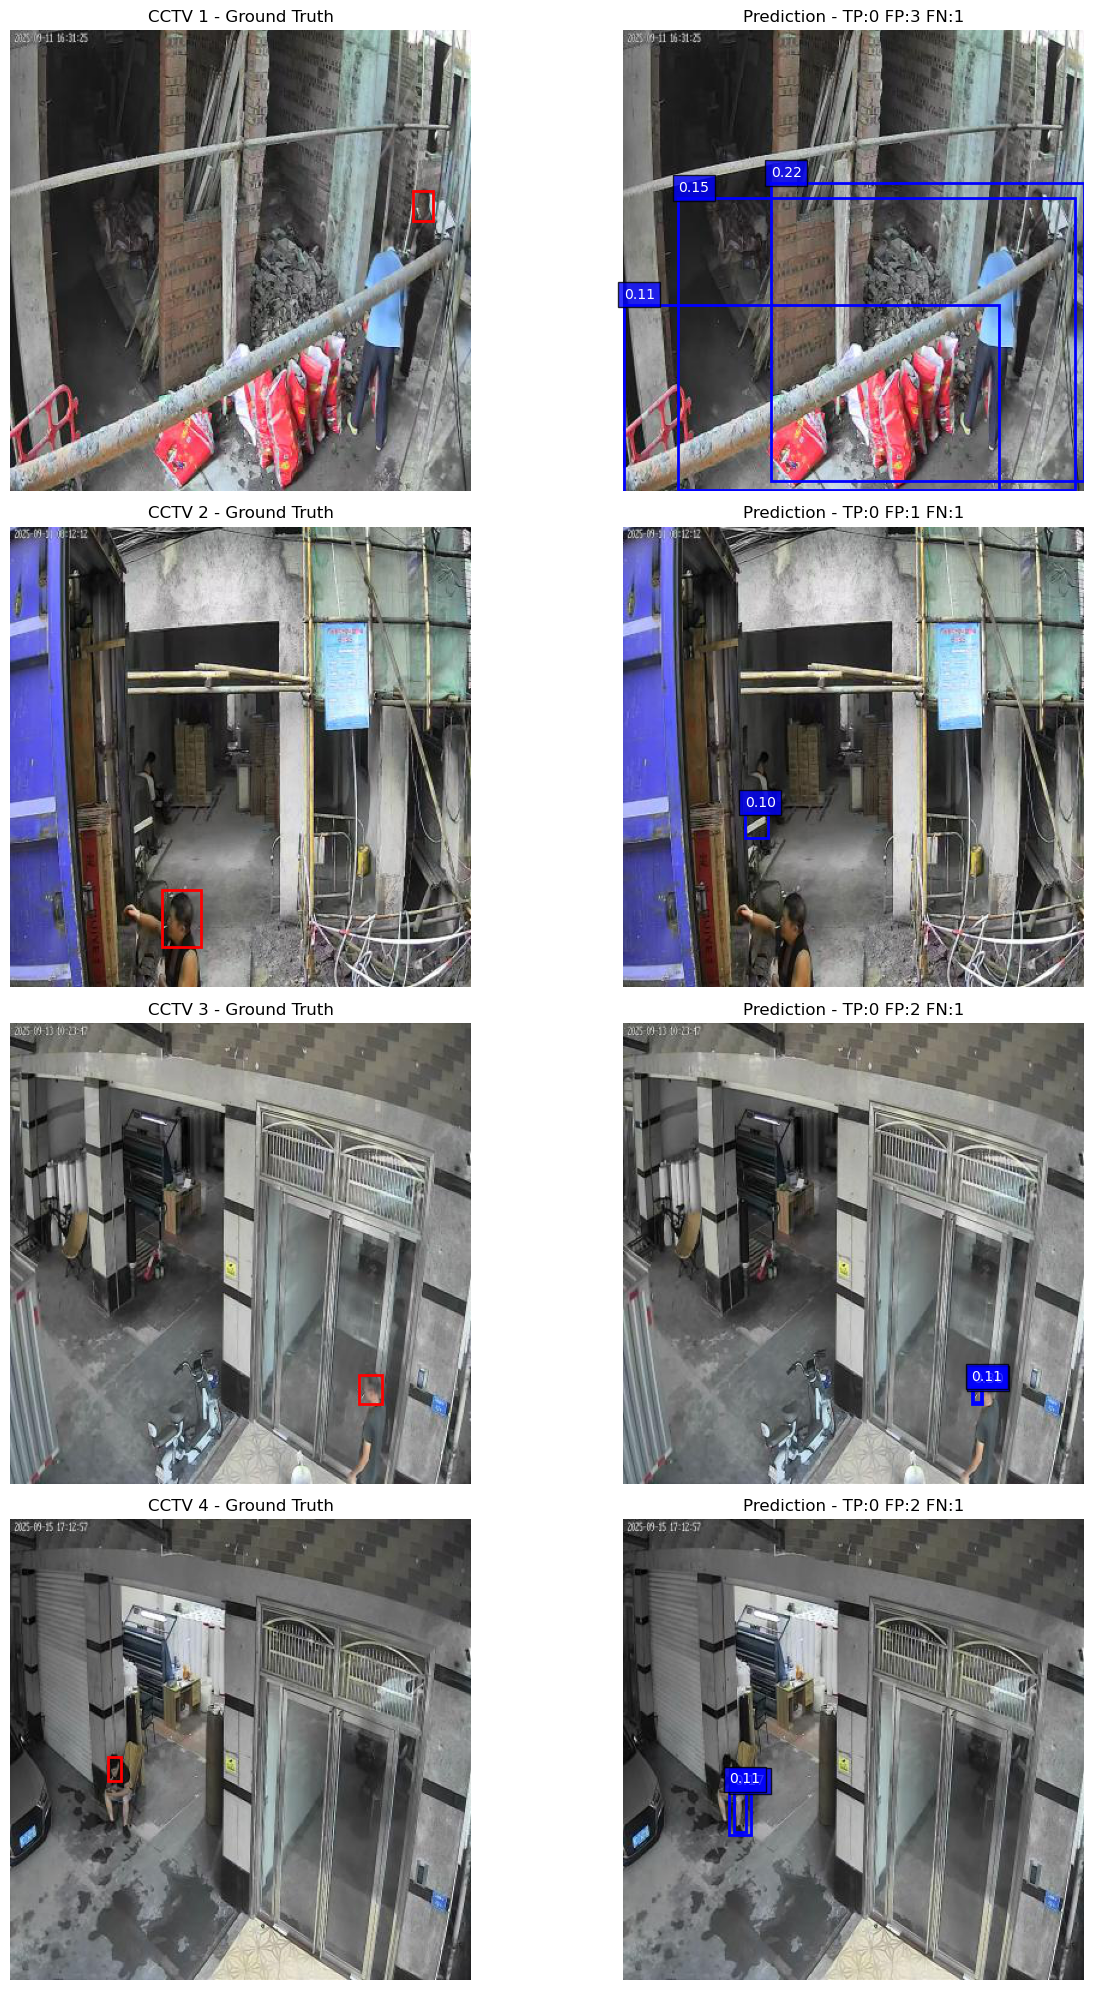


CCTV Manual Review


,Image,Ground_Truth_Boxes,Predicted_Boxes,TP,FP,FN,Smoking_Visually_Confirmed,Annotation_Correct,Notes
0,old_smoking_0001_alert_ab92a32a84eb4e3d9862afb...,1,3,0,3,1,Not Reviewed,Not Reviewed,
1,old_smoking_0003_alert_96710bc0bedc4057b57194b...,1,1,0,1,1,Not Reviewed,Not Reviewed,
2,old_smoking_0014_alert_c5fbcc582d504454a7770b4...,1,2,0,2,1,Not Reviewed,Not Reviewed,
3,old_smoking_0019_alert_c304587c8b154348b367767...,1,2,0,2,1,Not Reviewed,Not Reviewed,



Review Image Saved: C:\Users\Fix-Dell\Downloads\Smoking_Detection\Smoking_Detection_Results\cctv_manual_review.png
Review CSV Saved: C:\Users\Fix-Dell\Downloads\Smoking_Detection\Smoking_Detection_Results\cctv_manual_review.csv


In [13]:
from PIL import Image
from matplotlib.patches import Rectangle
import matplotlib.pyplot as plt
import pandas as pd

review_rows = []

fig, axes = plt.subplots(
    len(old_images), 2,
    figsize=(14, 5 * len(old_images)),
    squeeze=False
)

for row, img_path in enumerate(old_images):

    image = Image.open(img_path).convert("RGB")
    width, height = image.size

    gt_boxes = read_gt(
        label_dir / f"{img_path.stem}.txt",
        width,
        height
    )

    prediction = best_model.predict(
        source=str(img_path),
        conf=0.10,
        imgsz=640,
        verbose=False
    )[0]

    pred_boxes = [
        (
            tuple(box.xyxy[0].tolist()),
            float(box.conf[0])
        )
        for box in prediction.boxes
    ]

    matched = match_predictions(gt_boxes, pred_boxes)

    tp = len(matched)
    fp = len(pred_boxes) - tp
    fn = len(gt_boxes) - tp

    left = axes[row, 0]
    right = axes[row, 1]

    left.imshow(image)
    right.imshow(image)

    left.set_title(f"CCTV {row+1} - Ground Truth")
    right.set_title(f"Prediction - TP:{tp} FP:{fp} FN:{fn}")

    left.axis("off")
    right.axis("off")

    for x1, y1, x2, y2 in gt_boxes:

        left.add_patch(
            Rectangle(
                (x1, y1),
                x2-x1,
                y2-y1,
                fill=False,
                edgecolor="red",
                linewidth=2
            )
        )

    for i, (box, confidence) in enumerate(pred_boxes):

        x1, y1, x2, y2 = box

        color = "green" if i in matched else "blue"

        right.add_patch(
            Rectangle(
                (x1, y1),
                x2-x1,
                y2-y1,
                fill=False,
                edgecolor=color,
                linewidth=2
            )
        )

        right.text(
            x1,
            max(0, y1-5),
            f"{confidence:.2f}",
            color="white",
            bbox=dict(facecolor=color, alpha=0.8)
        )

    review_rows.append({
        "Image": img_path.name,
        "Ground_Truth_Boxes": len(gt_boxes),
        "Predicted_Boxes": len(pred_boxes),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Smoking_Visually_Confirmed": "Not Reviewed",
        "Annotation_Correct": "Not Reviewed",
        "Notes": ""
    })

plt.tight_layout()

review_image_path = result_dir / "cctv_manual_review.png"

plt.savefig(
    review_image_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

review_df = pd.DataFrame(review_rows)

review_csv_path = result_dir / "cctv_manual_review.csv"

review_df.to_csv(
    review_csv_path,
    index=False
)

print("\nCCTV Manual Review")
display(review_df)

print("\nReview Image Saved:", review_image_path.resolve())
print("Review CSV Saved:", review_csv_path.resolve())
